# Dimensionality Reduction Mini Project: Human Activity Recognition

We run K-Means and DBSCAN on the data before and after PCA and compare the results. We also try UMAP.

Dataset: [UCI Human Activity Recognition Using Smartphones](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones). Phone sensor readings from 30 people doing 6 activities, with 561 features. We merged train and test into one file (`har.csv`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
import umap

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the data

In [2]:
df = pd.read_csv("har.csv")
print(df.shape)
df.head()

(10299, 563)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


## 2. EDA

In [3]:
print(df.dtypes.value_counts())
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

float64    561
int64        1
str          1
Name: count, dtype: int64
Missing values: 0


Duplicate rows: 0


561 numeric features, plus `subject` (person id) and `Activity` (the label). No missing values or duplicates.

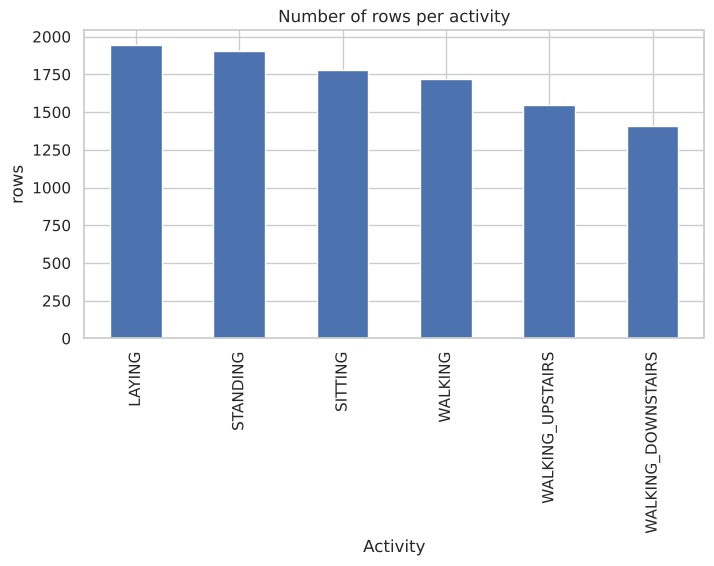

In [4]:
df["Activity"].value_counts().plot.bar(figsize=(8, 4))
plt.title("Number of rows per activity")
plt.ylabel("rows")
plt.show()

The 6 activities are fairly balanced.

In [5]:
df.iloc[:, :6].describe().round(2)

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z
count,10299.00,10299.00,10299.00,10299.00,10299.00,10299.00
mean,0.27,-0.02,-0.11,-0.61,-0.51,-0.61
std,0.07,0.04,0.05,0.44,0.50,0.40
min,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00
25%,0.26,-0.02,-0.12,-0.99,-0.98,-0.98
50%,0.28,-0.02,-0.11,-0.94,-0.84,-0.85
75%,0.29,-0.01,-0.10,-0.25,-0.06,-0.28
max,1.00,1.00,1.00,1.00,1.00,1.00


The features are already between -1 and 1.

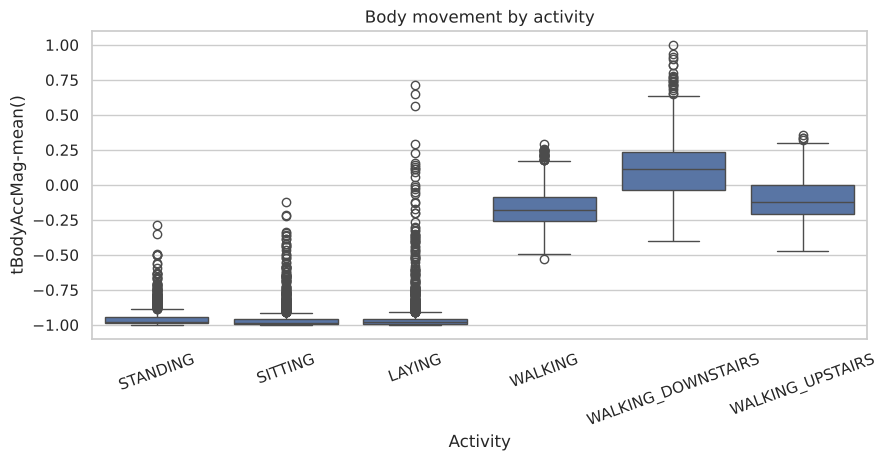

In [6]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="Activity", y="tBodyAccMag-mean()")
plt.xticks(rotation=20)
plt.title("Body movement by activity")
plt.show()

Walking activities have much more movement than sitting, standing and laying. So some groups should be easy to separate and others harder.

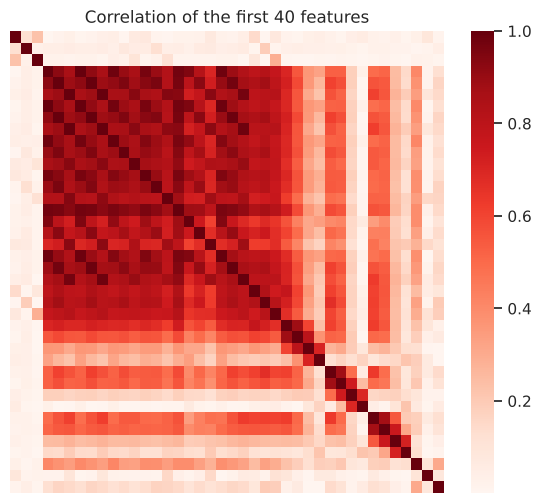

Feature pairs with correlation > 0.9: 8093


In [7]:
corr = df.iloc[:, :561].corr().abs()
plt.figure(figsize=(7, 6))
sns.heatmap(corr.iloc[:40, :40], cmap="Reds", xticklabels=False, yticklabels=False)
plt.title("Correlation of the first 40 features")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print("Feature pairs with correlation > 0.9:", (upper > 0.9).sum().sum())

Many features are highly correlated, so a lot of them repeat the same information. This is where dimensionality reduction helps.

## 3. Preparation
With 561 features the data is high dimensional. Distances between points become less meaningful (curse of dimensionality), which hurts K-Means and DBSCAN.

We drop `subject` and `Activity` and scale the features. `Activity` is only used at the end to check the clusters.

In [8]:
X = df.drop(columns=["subject", "Activity"])
y = df["Activity"]

X = StandardScaler().fit_transform(X)
print(X.shape)

(10299, 561)


For K-Means we use K = 6 because there are 6 activities.

To compare, we use:
- **ARI**: how close the clusters are to the real activities (1 = perfect, 0 = random).
- **Silhouette**: how well separated the clusters are. We always calculate it on the original 561 features so the comparison is fair.
- **Time** to run the clustering.

In [9]:
def run_kmeans(data):
    start = time.time()
    labels = KMeans(n_clusters=6, n_init=10, random_state=RANDOM_STATE).fit_predict(data)
    seconds = time.time() - start
    ari = adjusted_rand_score(y, labels)
    sil = silhouette_score(X, labels, sample_size=3000, random_state=RANDOM_STATE)
    return labels, seconds, ari, sil

In [10]:
def run_dbscan(data, eps):
    start = time.time()
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(data)
    seconds = time.time() - start
    mask = labels != -1  # -1 means noise
    n_clusters = len(set(labels[mask]))
    noise = (~mask).mean() * 100
    ari = adjusted_rand_score(y, labels)
    sil = silhouette_score(X[mask], labels[mask], sample_size=3000, random_state=RANDOM_STATE)
    return labels, seconds, ari, sil, n_clusters, noise

def plot_k_distance(data, eps):
    distances = NearestNeighbors(n_neighbors=10).fit(data).kneighbors(data)[0][:, -1]
    plt.figure(figsize=(7, 4))
    plt.plot(np.sort(distances))
    plt.axhline(eps, color="red", linestyle="--", label=f"eps = {eps}")
    plt.title("k-distance plot")
    plt.xlabel("Points (sorted)"); plt.ylabel("Distance to 10th neighbor")
    plt.legend()
    plt.show()

## 4. Before PCA (all 561 features)

### 4.1 K-Means

In [11]:
labels_raw, t_raw, ari_raw, sil_raw = run_kmeans(X)
print(f"Time: {t_raw:.2f}s  ARI: {ari_raw:.3f}  Silhouette: {sil_raw:.3f}")

Time: 1.75s  ARI: 0.420  Silhouette: 0.110


In [12]:
pd.crosstab(y, labels_raw)

col_0,0,1,2,3,4,5
Activity,,,,,,
LAYING,54,0,0,5,329,1556
SITTING,1238,0,0,1,447,91
STANDING,1346,0,0,0,560,0
WALKING,0,84,741,897,0,0
WALKING_DOWNSTAIRS,0,214,882,310,0,0
WALKING_UPSTAIRS,0,9,297,1236,2,0


Laying is mostly in one cluster, but sitting and standing are mixed together and the 3 walking types are mixed too.

### 4.2 DBSCAN

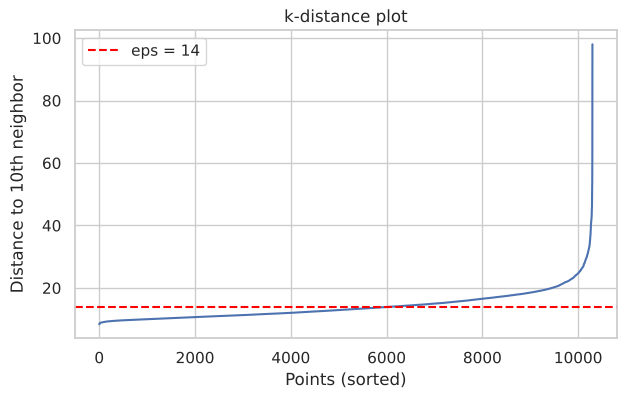

eps=12  clusters: 16  noise: 50.2%  ARI: 0.193


eps=14  clusters: 9  noise: 30.3%  ARI: 0.288


eps=16  clusters: 8  noise: 17.2%  ARI: 0.056


eps=18  clusters: 3  noise: 8.3%  ARI: 0.019


In [13]:
plot_k_distance(X, eps=14)

for eps in [12, 14, 16, 18]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    print(f"eps={eps}  clusters: {len(set(labels)) - (-1 in labels)}  "
          f"noise: {(labels == -1).mean() * 100:.1f}%  ARI: {adjusted_rand_score(y, labels):.3f}")

In 561 dimensions the distances are big and close to each other, so a small change in eps changes everything. eps = 14 gave the best ARI.

In [14]:
labels_db_raw, t_db_raw, ari_db_raw, sil_db_raw, n_db_raw, noise_db_raw = run_dbscan(X, eps=14)
print(f"Clusters: {n_db_raw}  Noise: {noise_db_raw:.1f}%  Time: {t_db_raw:.2f}s  ARI: {ari_db_raw:.3f}  Silhouette: {sil_db_raw:.3f}")

Clusters: 9  Noise: 30.3%  Time: 1.31s  ARI: 0.288  Silhouette: 0.313


In [15]:
pd.crosstab(y, labels_db_raw)

col_0,-1,0,1,2,3,4,5,6,7,8
Activity,,,,,,,,,,
LAYING,237,1707,0,0,0,0,0,0,0,0
SITTING,147,1630,0,0,0,0,0,0,0,0
STANDING,101,1805,0,0,0,0,0,0,0,0
WALKING,666,0,911,0,16,17,25,38,37,12
WALKING_DOWNSTAIRS,1289,0,117,0,0,0,0,0,0,0
WALKING_UPSTAIRS,679,0,856,9,0,0,0,0,0,0


DBSCAN basically finds 2 groups, moving and not moving, and marks about a third of the data as noise.

## 5. PCA

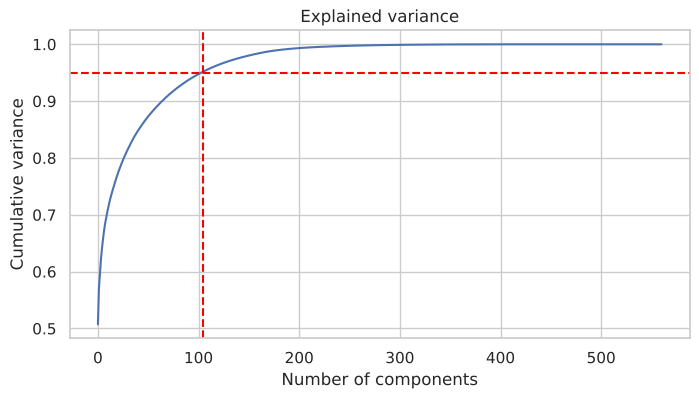

Components for 95% variance: 104
Variance kept by 2 components: 0.57


In [16]:
pca_full = PCA().fit(X)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = np.argmax(cum_var >= 0.95) + 1

plt.figure(figsize=(8, 4))
plt.plot(cum_var)
plt.axhline(0.95, color="red", linestyle="--")
plt.axvline(n_95, color="red", linestyle="--")
plt.title("Explained variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance")
plt.show()

print("Components for 95% variance:", n_95)
print("Variance kept by 2 components:", round(cum_var[1], 3))

Only about a fifth of the features are needed to keep 95% of the information. 2 components keep a bit more than half.

In [17]:
X_pca95 = PCA(n_components=n_95, random_state=RANDOM_STATE).fit_transform(X)
X_pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
print(X_pca95.shape, X_pca2.shape)

(10299, 104) (10299, 2)


## 6. After PCA

### 6.1 K-Means

In [18]:
labels_pca95, t_pca95, ari_pca95, sil_pca95 = run_kmeans(X_pca95)
print(f"PCA 95% -> Time: {t_pca95:.2f}s  ARI: {ari_pca95:.3f}  Silhouette: {sil_pca95:.3f}")

labels_pca2, t_pca2, ari_pca2, sil_pca2 = run_kmeans(X_pca2)
print(f"PCA 2   -> Time: {t_pca2:.2f}s  ARI: {ari_pca2:.3f}  Silhouette: {sil_pca2:.3f}")

PCA 95% -> Time: 0.34s  ARI: 0.419  Silhouette: 0.109


PCA 2   -> Time: 0.04s  ARI: 0.274  Silhouette: 0.096


PCA 95% gives almost the same result as all 561 features but runs faster. PCA 2 is too much, we lose information and the ARI drops.

### 6.2 DBSCAN (2 components)

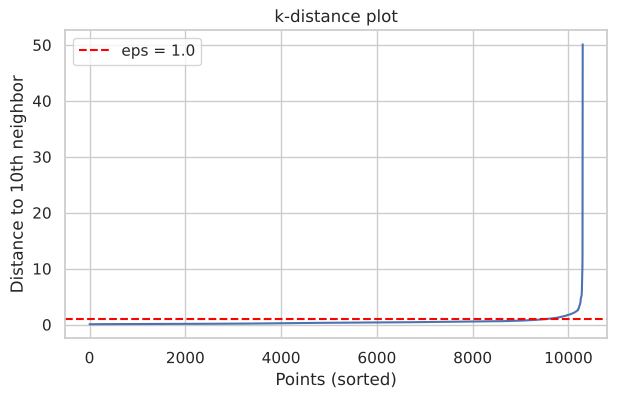

eps=0.5  clusters: 24  noise: 16.5%  ARI: 0.285


eps=1.0  clusters: 6  noise: 5.1%  ARI: 0.321


eps=1.5  clusters: 4  noise: 2.4%  ARI: 0.328


eps=2.0  clusters: 1  noise: 1.0%  ARI: 0.001


In [19]:
plot_k_distance(X_pca2, eps=1.0)

for eps in [0.5, 1.0, 1.5, 2.0]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_pca2)
    print(f"eps={eps}  clusters: {len(set(labels)) - (-1 in labels)}  "
          f"noise: {(labels == -1).mean() * 100:.1f}%  ARI: {adjusted_rand_score(y, labels):.3f}")

In [20]:
labels_db_pca2, t_db_pca2, ari_db_pca2, sil_db_pca2, n_db_pca2, noise_db_pca2 = run_dbscan(X_pca2, eps=1.0)
print(f"Clusters: {n_db_pca2}  Noise: {noise_db_pca2:.1f}%  Time: {t_db_pca2:.2f}s  ARI: {ari_db_pca2:.3f}  Silhouette: {sil_db_pca2:.3f}")

Clusters: 6  Noise: 5.1%  Time: 0.08s  ARI: 0.321  Silhouette: 0.218


After PCA the k-distance curve is much clearer and the noise drops a lot. But it still only finds moving vs not moving.

### 6.3 Bonus: different number of components

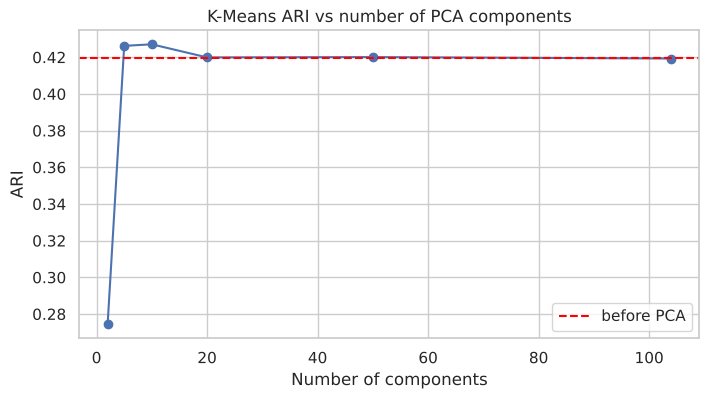

In [21]:
components = [2, 5, 10, 20, 50, n_95]
aris = []
for n in components:
    X_n = PCA(n_components=n, random_state=RANDOM_STATE).fit_transform(X)
    aris.append(run_kmeans(X_n)[2])

plt.figure(figsize=(8, 4))
plt.plot(components, aris, marker="o")
plt.axhline(ari_raw, color="red", linestyle="--", label="before PCA")
plt.title("K-Means ARI vs number of PCA components")
plt.xlabel("Number of components"); plt.ylabel("ARI")
plt.legend()
plt.show()

From 5 components and up the result is the same as using all 561 features. Only 2 components is too few.

## 7. K-Means on UMAP

In [22]:
start = time.time()
X_umap10 = umap.UMAP(n_components=10, random_state=RANDOM_STATE).fit_transform(X)
print(f"UMAP took {time.time() - start:.1f}s")

labels_umap, t_umap, ari_umap, sil_umap = run_kmeans(X_umap10)
print(f"UMAP 10 -> Time: {t_umap:.2f}s  ARI: {ari_umap:.3f}  Silhouette: {sil_umap:.3f}")

UMAP took 38.9s


UMAP 10 -> Time: 0.05s  ARI: 0.605  Silhouette: 0.076


In [23]:
pd.crosstab(y, labels_umap)

col_0,0,1,2,3,4,5
Activity,,,,,,
LAYING,58,0,1883,1,2,0
SITTING,1765,0,9,0,3,0
STANDING,1906,0,0,0,0,0
WALKING,0,548,0,1023,66,85
WALKING_DOWNSTAIRS,0,1242,0,82,0,82
WALKING_UPSTAIRS,0,176,0,20,403,945


UMAP gives the best ARI. It separates the walking types much better than before. Sitting and standing are still hard to tell apart.

## 8. Visualization
### Clusters before vs after PCA
All plots use PC1 and PC2 so we can compare them on the same map.

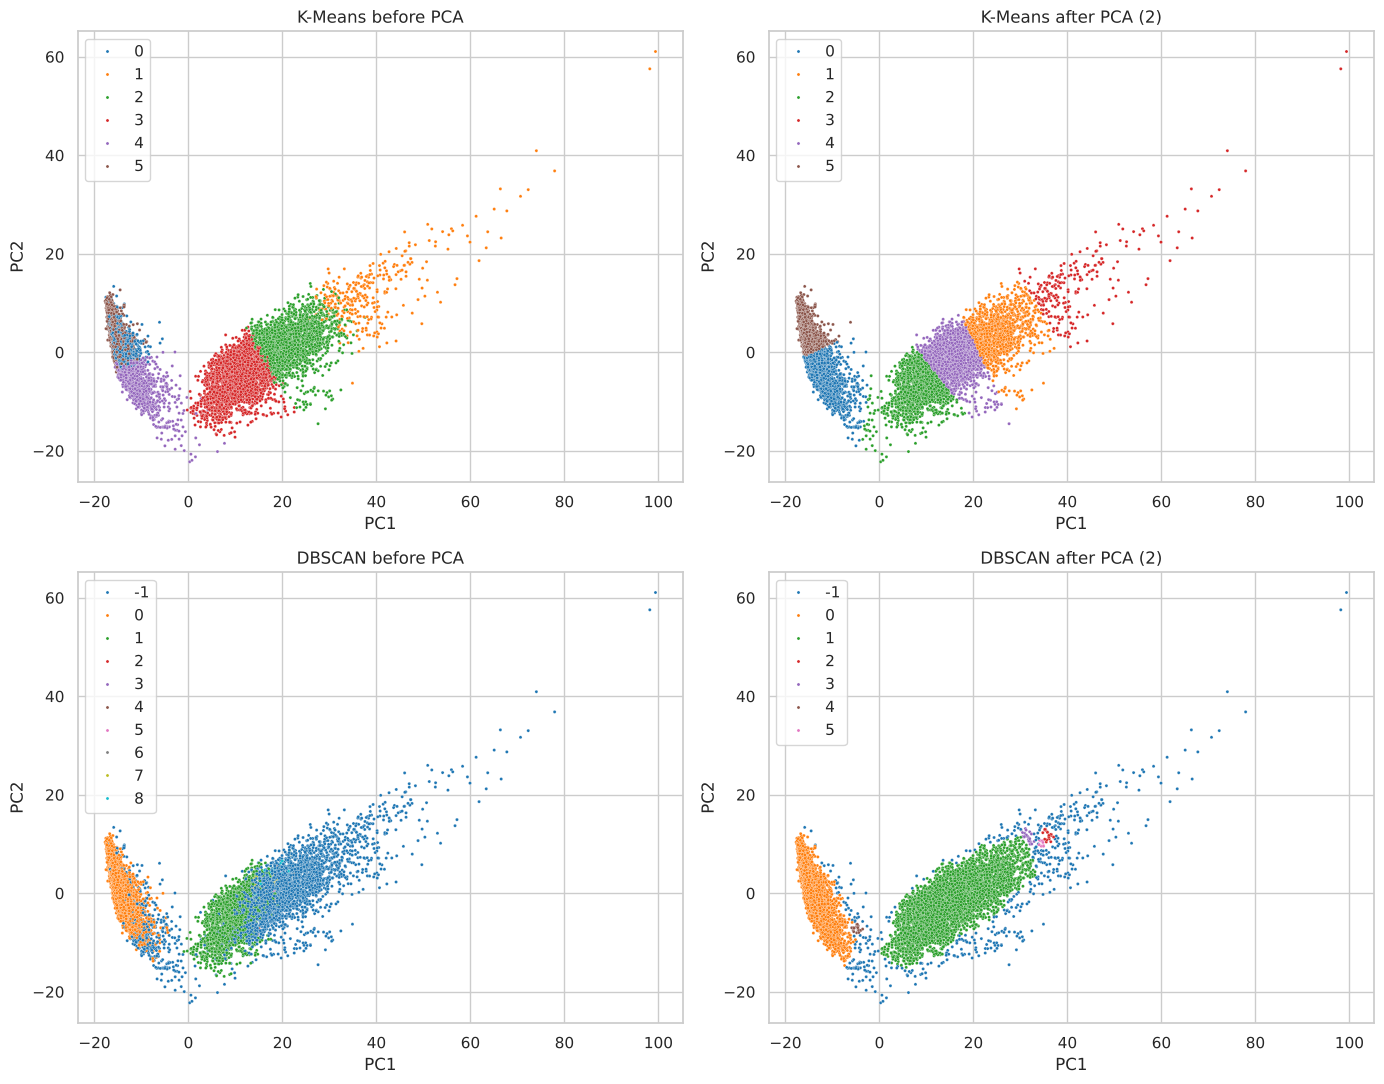

In [24]:
plots = [(labels_raw, "K-Means before PCA"), (labels_pca2, "K-Means after PCA (2)"),
         (labels_db_raw, "DBSCAN before PCA"), (labels_db_pca2, "DBSCAN after PCA (2)")]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (labels, title) in zip(axes.flat, plots):
    sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=labels, palette="tab10", s=5, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

- K-Means before PCA: the clusters follow the shape of the data even on this map.
- K-Means after PCA: it just cuts the map into slices along PC1.
- DBSCAN: both find the 2 big groups. Before PCA a lot of points are noise (-1), after PCA much less.

### PCA vs t-SNE vs UMAP
We reduce to 2D and color by the real activity. t-SNE is only for plots, not for clustering.

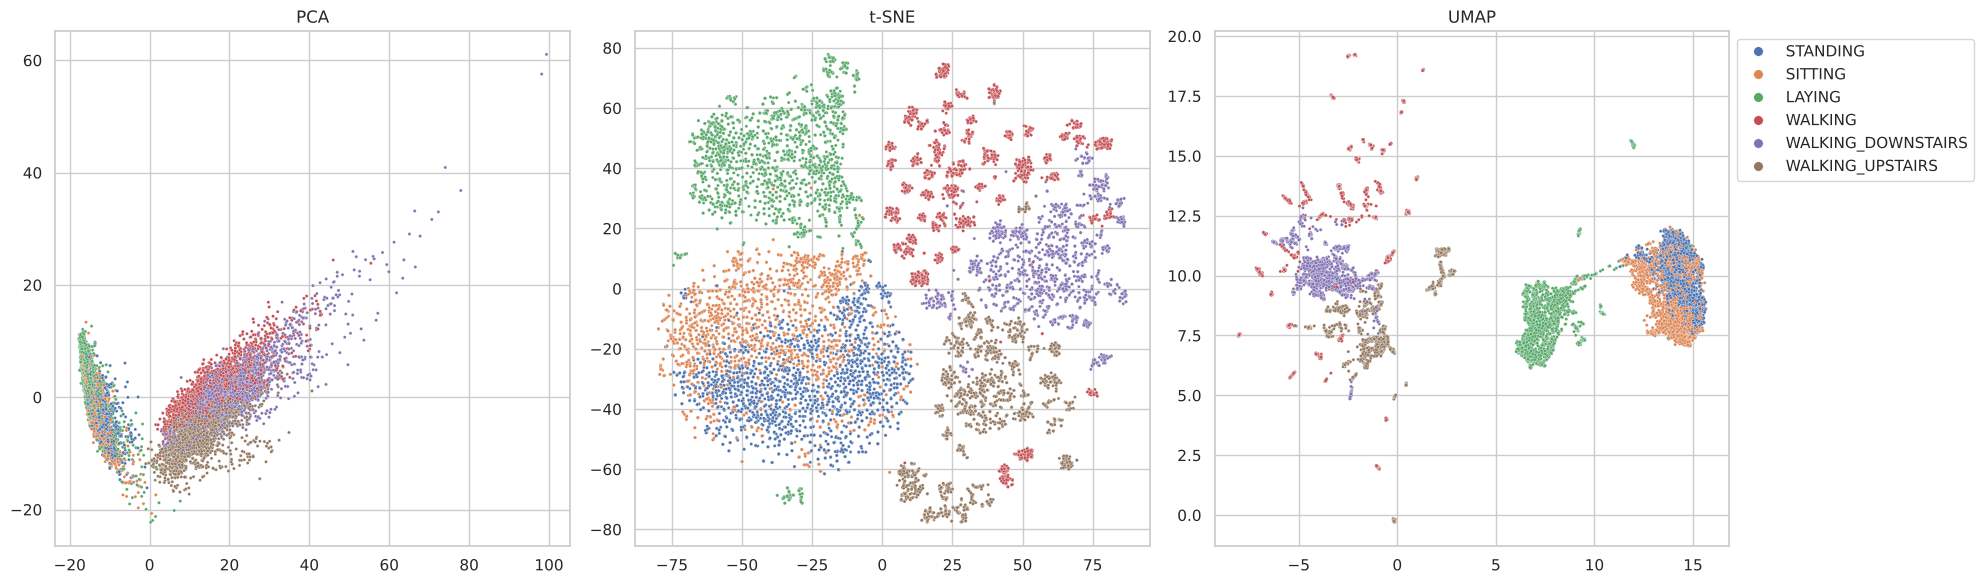

In [25]:
X_tsne = TSNE(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
X_umap2 = umap.UMAP(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, data, title in zip(axes, [X_pca2, X_tsne, X_umap2], ["PCA", "t-SNE", "UMAP"]):
    sns.scatterplot(x=data[:, 0], y=data[:, 1], hue=y, s=5, ax=ax, legend=(title == "UMAP"))
    ax.set_title(title)
axes[2].legend(markerscale=3, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

- PCA: two big groups, moving and not moving, but the activities inside them overlap.
- t-SNE and UMAP: the activities are much clearer. Sitting and standing still overlap.

## 9. Comparison

In [26]:
print("K-Means")
print(f"  Before PCA (561):   ARI {ari_raw:.3f} | Silhouette {sil_raw:.3f} | Time {t_raw:.2f}s")
print(f"  After PCA 95%:      ARI {ari_pca95:.3f} | Silhouette {sil_pca95:.3f} | Time {t_pca95:.2f}s")
print(f"  After PCA (2):      ARI {ari_pca2:.3f} | Silhouette {sil_pca2:.3f} | Time {t_pca2:.2f}s")
print(f"  After UMAP (10):    ARI {ari_umap:.3f} | Silhouette {sil_umap:.3f} | Time {t_umap:.2f}s")
print()
print("DBSCAN")
print(f"  Before PCA (561):   ARI {ari_db_raw:.3f} | Silhouette {sil_db_raw:.3f} | Noise {noise_db_raw:.1f}% | Clusters {n_db_raw} | Time {t_db_raw:.2f}s")
print(f"  After PCA (2):      ARI {ari_db_pca2:.3f} | Silhouette {sil_db_pca2:.3f} | Noise {noise_db_pca2:.1f}% | Clusters {n_db_pca2} | Time {t_db_pca2:.2f}s")

K-Means
  Before PCA (561):   ARI 0.420 | Silhouette 0.110 | Time 1.75s
  After PCA 95%:      ARI 0.419 | Silhouette 0.109 | Time 0.34s
  After PCA (2):      ARI 0.274 | Silhouette 0.096 | Time 0.04s
  After UMAP (10):    ARI 0.605 | Silhouette 0.076 | Time 0.05s

DBSCAN
  Before PCA (561):   ARI 0.288 | Silhouette 0.313 | Noise 30.3% | Clusters 9 | Time 1.31s
  After PCA (2):      ARI 0.321 | Silhouette 0.218 | Noise 5.1% | Clusters 6 | Time 0.08s


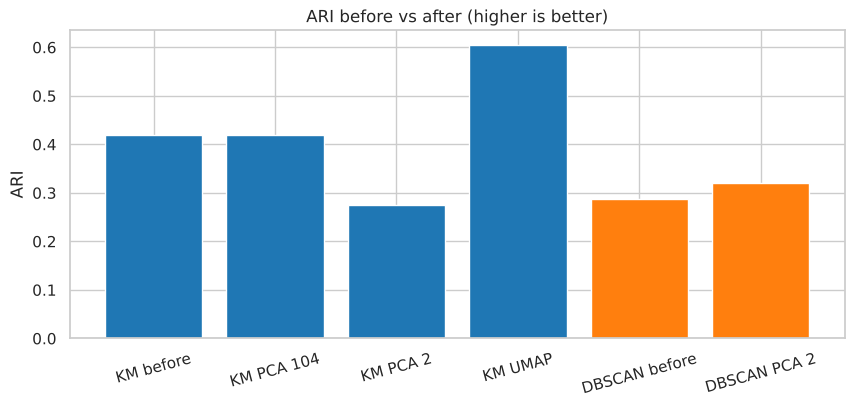

In [27]:
names = ["KM before", f"KM PCA {n_95}", "KM PCA 2", "KM UMAP", "DBSCAN before", "DBSCAN PCA 2"]
aris = [ari_raw, ari_pca95, ari_pca2, ari_umap, ari_db_raw, ari_db_pca2]
colors = ["tab:blue"] * 4 + ["tab:orange"] * 2

plt.figure(figsize=(10, 4))
plt.bar(names, aris, color=colors)
plt.title("ARI before vs after (higher is better)")
plt.xticks(rotation=15)
plt.ylabel("ARI")
plt.show()

**K-Means**
- Before vs PCA 95%: same ARI, but several times faster with a fifth of the features.
- Before vs PCA 2: ARI drops from 0.42 to 0.27.
- UMAP: best ARI (about 0.6).

**DBSCAN**
- Before vs PCA 2: noise drops from 30% to 5%, and ARI goes from 0.29 to 0.32.
- Both versions only split moving vs not moving.

**K-Means vs DBSCAN**
- K-Means does better here because the groups are close to each other and similar in density.

## 10. Analysis

**How did PCA affect clustering results?**
With 95% of the variance, K-Means stayed the same and got faster. With only 2 components K-Means got worse, but DBSCAN got a bit better and had much less noise.

**Did visualization become clearer?**
Yes, with 2 components we can actually plot the clusters. But only moving vs not moving is clear, the activities inside overlap.

**Did you lose important information?**
With 2 components yes, they keep only 57% of the variance, and that's why K-Means dropped. With 95% we lost almost nothing.

**Which approach is better and why?**
PCA with enough components (95%). Same results, faster, and fewer features. 2 components are good for plots, not for clustering.

## 11. Conclusion (Key Insights)
- The data has 561 features, but many of them repeat the same information.
- PCA with 95% variance kept the same K-Means quality and was faster. Even 5 components were enough.
- 2 PCA components are good for plots, not for clustering.
- DBSCAN struggled with 561 features. After PCA it had much less noise, but it still found only 2 groups.
- UMAP gave the best clusters, and t-SNE and UMAP show the activities more clearly than PCA.
- Sitting vs standing stayed hard in every case, the sensor data for them is very similar.